In [ ]:
# a = 42, b = 42, это две ссылки на один и тот же объект в памяти, а не два разных значения

# раньше инты были ограниченные в питоне, но сейчас все еще есть ограничения, но не бесконечное, int 4 байта, - 2^31 ... (погуглить и дописать)

# питон может даже больше чем 64 бита использовать при обычной арифметике, если архитектура пк позволяет, и уже потом использовать длинную арифметику (операции в столб и каждый разряд большое число)

# a = 42. - double (не float ,возможно в питоне нет float), 8 байт - (1 бит на знак, эксп, мант), (too complement почитать про это), в питоне все числа со знаком кроме unsigned (unsigned long long name = -1; (max число в плюсах)) Также есть статическая точка и плавающая, тоже об этом почитать стоит

# Кодировки для символов есть разные, utf8-16 (обычно utf-8 кроме винды используется везде), строки в питоне не изменяемые, для хеширования строк как ключей чтобы посчитать хеш для строки один раз и потом хэш не поменяется, строку можно просто перезаписать, но не изменить

# -13 % 5 = 2 остаток будет, как в плюсах (почитать почему)

# 10. ** 3 = 1000. - сохранит исходный тип

# 3 ^ 2 - 1 (xor операция)

# 2 | 1 - побитовое или= 3

# 2 & 1= 0 # сдвиги 1 << 5, 1 >> 5 (поделить на 2 в степени ...)

# строки можно умножать, складывать, срезать '1234234'[0] ... [-1] [0:5:2] переворот [::-1]

# a = '123456789'[-1: len(a) - 1: -1] перевернет строку



`Питон` - динамически типизированный язык


*Динамически типизированный* - значит тип определяется во время работы программы, а не при ее написании или комипиляции

### Принято делить ЯП по несокльким группам


#### По способу выполнения кода:

- *Компилируемые* - специальная программа-компилятор берет весь код и переводит его в один исполняемый файл, то есть, допустим в файл `.exe` `c++, rust, go` Долгий запуск, бытсрая работа

- *Интерпретируемые* - специальная программа-интерпритатор читает код строку за стркоой прямо во время запуска и сразу выполняет его `python, php`. Быстрый запуск, медленная работа

- *Гибридные* - код-сначала компилируется в промежуточный формат, байт-код, а специальная виртуальная машина компилирует его в машинный код (JIT-компиляция). Ну и это компромис между скоростью запуска и скоростью работы программы


#### По типизации:

- *Статическая* - тип сущности известен на момент написания кода / компиляии, его надо явно задавать в коде и нельзя менять
- *Динамическая* - тип сущности становится известен во время запуска программы, переменная может менять тип


*Плюс к этому:*
- Строгая (Python) - нельзя смещивать разные типы данных (число сложить со строкой)
- Слабая (JS) - можно смешивать разные типы, язык сам пытается привести типы

#### По уровню:

- Низкоуровневые
- Высокоуровневые

#### По парадигме

- *Императивные* (C, Pascal) - код пишется как последовательность инструкций
- *ООП* - программа строится вокруг объектов
- *ФП* - программа предствляет собой цепочку математических функций, где переменная меняет свое состояния (Haskel, Scala, Elixir)

В питоне все является ссылками, то есть если в памяти есть число 42, то переменные a и b на самом деле ссылаются на одно и тоже значение

In [ ]:
a = 42, b = 42

# Целочисленная арифметика

Сейчас в питоне нет ограничений на длину числа `int`, оно ограничивается только размером памяти компьютера, это в Python3 появилось

Типа `long` также нет, он объединен с `Int` типом

Питон числа разбивает на блоки по 30 бит, то есть по 30 символов, не по 32 потому что нужно избежать переполнения при умножении

- Например, число 2^100 хранится как массив из 4 элементов по 30 бит каждый
- Его общая память составляет 40 байт, потому что 24 байта на заголовок + 4*4 байта ~ 40 байт

В СPython реализация интового числа представлена в виде объекта, который содержит заголовок, состоящий из определенных служебных полей, которые занимают определенное количество памяти, например:

#### Упрощенная структура из исходников Cpython

```python
type struct {
    PyObject_VAR_HEAD, - заголовок, примерное 24 или 28 байт
    digit ob_digit[1]; - массив цифр по 30 бит
} PyLongObject;

 ```

Размер заголовка зависит от того, какая архитектура процессора, 32 или 64, обычно на 64 битных по 28 для малых чисел используется


Любая сущность в питоне потсроена на основе `PyObject` из `C` и которая тащит за собой в памяти как минимум два поля в заголовке, а именно:

- `ob_refcnt` счетчик ссылок, если на один объект в памяти (пусть будет число 42) есть несколько ссылок, то память занята, но если вдруг это число = 0, то память освобождается 


```python
a = 42          # refcnt = 1
b = a           # refcnt = 2  
del a 
``` 


- `ob_type` указатель на тип
Благодаря этому питон динамически типизированный язык и во время выполнения он знает о типе переменнной


Для чисел добавляется еще всегда поле `ob_size`, далее из из документации:

*Он есть у объектов, которые имеют некоторое представление о длине*

Рассмотрим то, как число 0 представлено внутри памяти питона:

Памяти выделяется 32 бита, 30 под число и 2 под запас

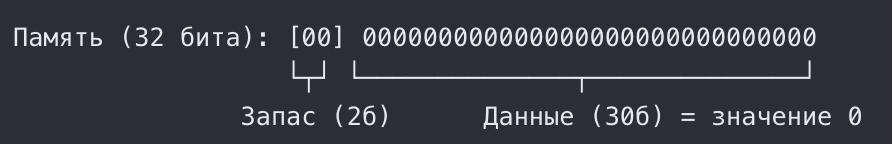

Так как само 30-битное число = 0, то `ob_size = 0`, то есть само число ничего не весит, но в объекте уже выделено 4 байта под само число и 24 под заголовки, то есть 28 байт в сумме

Теперь рассмотрим то, как число 1 представлено в памяти питона:

Памяти выделяется 32, 30 под число, 2 про запас

Но, теперь `ob_size` = 1, так как в 30 разрядах появилась единица

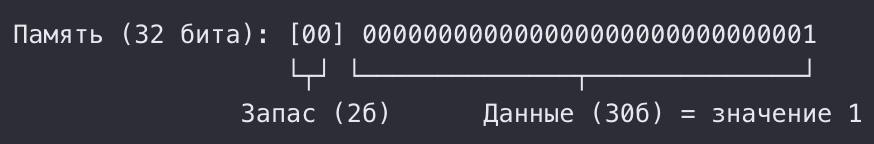

Так как само 30-битное число = 1, то `ob_size = 1`, в объекте уже выделено 4 байта под само число и 24 под заголовки, то есть 28 байт в сумме

Собственно, все числа до 2^30 - 1 будут весить по 28 байт

Для числа 2^30, которое не помещается в 28 байт, мы просто пристаиваем еще одну коробку в 4 байта (то есть 32 бита) и размерность увеличивается до 2^60 - 1

Почему под блок 4 байта? Потому что в питоне договорняк, что под разряд числа мы выделяем 32 бита, (30 на число, 2 на запас над операциями), в 32 бита влезает 4 байта (1 байт = 8 бит, их как раз помещается 4)

Подведем итоги:
- 24 байта под заголовки (при 64 разрядной архитектуре)
- 4 байта под 2^30 - 1 чисел (30 под число, 2 на длинную арифметику)
- Потом мы при переполнении, начиная с 2^30 добавялем по 4 байта под число и размер числа увеличивается до 32 байтов

# Отрицательные целые числа

В питоне то, что число отрицательное, можно узнать по все тому же полю `ob_size` у объекта. Если оно отрицательное, значит уже и само число отрицательное. Ну а дальше там применяется классическая процедура представления отрицательных чисел в памяти ПК

Получше разобрать эту тему

# Вещественные числа

# Вещественные отрицательные числа

## Операции над вещественными числами (главное вычитание)

# Строки

In [2]:
' abc '.join('123')

'1 abc 2 abc 3'

In [3]:
'123'.split('3')

['12', '']

In [ ]:
a = '12 345 6 /t7 89' # в каких то версиях может пропасть символ табуляции на сплите по пустой строке ,но не в 3 10
a.split()


['12', '345', '6', '/t7', '89']

In [8]:
f'{10 + 30}'

'40'

In [9]:
f'{10 + 20:05d}'

'00030'

In [11]:
f'{10 + 20:05d}, {10 + 20=}'

'00030, 10 + 20=30'

In [12]:
r'\t\n\r'

'\\t\\n\\r'

In [13]:
print(r'\t\n\r123')

\t\n\r123


In [14]:
'%d + %d = %d' % (10, 20, 30)

'10 + 20 = 30'

In [15]:
'{} + {} = {}'.format(10, 20, 30)

'10 + 20 = 30'

In [ ]:
f = '{} + {} = {}'
f = '{0} + {2} = {1} ({2})'
f.format(10, 20, 30)

'10 + 30 = 20 (30)'

In [49]:
# списки - изменяемая послед элементов, в нем тип данных наз-ся ссылка
a = [1, 2, 3, 4, 5, 6]
a.append(10)

In [21]:
a.extend(a)
a

[1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10]

In [ ]:
# a[start:stop:step]
a[0:2]

[1, 2]

In [75]:

a[1:3]  = [5, 6, 7, 8]
a

NameError: name 'a' is not defined

In [25]:
a + a

[1,
 5,
 6,
 7,
 8,
 7,
 8,
 4,
 5,
 6,
 10,
 1,
 2,
 3,
 4,
 5,
 6,
 10,
 1,
 5,
 6,
 7,
 8,
 7,
 8,
 4,
 5,
 6,
 10,
 1,
 2,
 3,
 4,
 5,
 6,
 10]

In [50]:
a * 3

[1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10]

In [ ]:
a.append(a)
a
# ссылку на список положили в список

[1, 5, 6, 7, 8, 7, 8, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10, [...], [...]]

In [ ]:
a = [[1, 2]] * 3 # поменяли объект по одной и той же ссылке, список буквально явялется вектором как в плюсах почитать
a[0].append(3)
a

[[1, 2, 3], [1, 2, 3], [1, 2, 3]]

In [ ]:
# кортеж - нельзя менять
a = (1, 2, 3, 4)
a[1] = 2

TypeError: 'tuple' object does not support item assignment

In [32]:
(1)

1

In [33]:
(1,)

(1,)

In [ ]:
# неизменяемые потому что хеширование и не надо ключи пересоздавать

In [ ]:
# множества, нельзя обратится по индексу и тд
a = {1, 2, 3, 4, 5}

In [ ]:
a = {'a' : 1, 'b' : 2, 3: 4} # ассоциированный массив
a

{'a': 1, 'b': 2, 3: 4}

In [36]:
a['b']

2

In [37]:
a[(1, 2)] = 5

In [38]:
a[[1, 2]] = 5 # нельзя

TypeError: unhashable type: 'list'

In [39]:
a

{'a': 1, 'b': 2, 3: 4, (1, 2): 5}

In [ ]:
# new_list = [выражение for элемент in итерируемый_объект] list comprehention



In [ ]:
# frozen set, это просто класс в питоне, ничего такого, это обычный сет но который нельзя изменять

# [] vs {} - просто более удобная абстракция, 
# то есть если мы знаем заранее все элементы, то лучше использовать [], иначе лучше использовать {} если мы не знаем

In [ ]:
a = None
# значит ничего, но потом появится, нужно для того чтобы выделить память, потому что в питоне может ссылаться на чтото, также None всегда один объект на весь исполняемый файл

type(None)() is None

True

In [ ]:
# Nan - не число, нужно для того чтобы покать, что результат не может быть числом, не существует такого числа
# все операции с nan это nan
# null нет в питоне из-за его особенностей, так как ссылка всегда должна ссылаться на какой то объект в питоне, то есть для этого есть None

### Первая задачка на добавление элементов в массив по умолчанию

In [15]:
def append_to_list(what, to=[]):
    to.append(what)
    return to

a = []
append_to_list(42, a)
append_to_list(43, a)

# вот такая проблемка может быть
append_to_list(42), append_to_list(42), append_to_list(42)


([42, 42, 42], [42, 42, 42], [42, 42, 42])

Разберем по порядку то, почему такая проблема возникает. Это связано в первую очередь со ссылками и то, как питон создает новые объекты

```
def append_to_list(what, to=[]):
```

Тут в параметре создается новый объект-список `to=[]` которые создается всего 1 раз на момент когда питон читает и выгружает эту функции в память. Поэтому когда мы вызовем функцию неправильно, то есть не передадим вторым параметром массив при вызове функции, то есть сделаем так:

```
append_to_list(42)
append_to_list(42)
```

то по итогу мы каждый раз будем добавлять элемент в один и тот же список `to`, который мы когда-то объявили в памяти

Еще хуже можно сделать при вызоыве функции в строку через запятую, в таком случае создается кортеж (tuple), это неизменяемый аналог обычного списка, по итогу при вызове первой функции она вернет [42], при вызове второй [42, 42], и потом так как эти фукнции возвращают не значение, а ссылку на один и тот же объект в памяти, то есть массив `to=[]`, у нас оно соберется в один двумерный массив

Аналог операции в строку выглядит вот так:

In [14]:
res1 = append_to_list(42)
res2 = append_to_list(42)
res3 = append_to_list(42)

res = [res1, res2, res3]
res

[[42, 42, 42], [42, 42, 42], [42, 42, 42]]

Эта проблема может возникать со всем, что является ссылкой

Дефолтные параметры объекта можно узнать следующим образом

In [16]:
append_to_list.__defaults__

([42, 42, 42],)

Ну и как видно, тут параметр по дефолту уже не чистый массив, а загрязненный

Первый фикс данной проблемы заключается в том, что мы будем возвращать не ссылку на один и тот же массив, а будем спред оператором возвращать копию массива

In [20]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
# указатель объекта
# ids = [id(a)]

# for i in range(5):
#     a = append_to_list(42, a)
#     ids.append(id(a))

# ids
append_to_list(43)
append_to_list(43)


[43]

In [24]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
# функция id позволяет получить указатель объекта
ids = []

for i in range(5):
    a = append_to_list(42, a)
    ids.append(a)

ids
# append_to_list(43)
# append_to_list(43)


[[42], [42, 42], [42, 42, 42], [42, 42, 42, 42], [42, 42, 42, 42, 42]]

По результату видно, что получаются ращные списки, для наглядности выведем их ссылки с помощью функции `id()`

In [26]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
ids = [id(a)]
a

[]

In [27]:
for i in range(5):
    a = append_to_list(42, a)
    ids.append(id(a))

ids

[4418119360, 4418445632, 4417709504, 4418445632, 4417709504, 4418445632]

Ну и по ссылкам на объекты видно, что все списки разные

Из возможных гипотетических проблем данной реализации:
- могут совпасть адреса в памяти, если старый объект был удален сборщиком мусора, но не в данном случае так как все списки сохранены в массив ids

Но главная проблема следующая:
- В данной реализации сигнатура функции обещает добавить элемент в массив, а по факту возвращает новый список со старыми элементами и новым добавленым, а не просто добавляет в список, и это очень плохо

Поэтому можно решить задачу следующим, эталонным способом:

In [ ]:
a = []
ids = [id(a)]

def append_to_list(what, to=[]):
    if to is None:
        to = []
    to.append(what)
    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4418217408, 4418217408, 4418217408, 4418217408, 4418217408, 4418217408]

По айдишникам видно, что мы честно добавляем элемент в один и тот же список, потому что они одинаковые

In [30]:
a

[0, 1, 2, 3, 4]

Значения тоже все верные

Есть еще пример более запутанной реализации данной функции, который обычно не рекомендуют использовать из-за сложности чтения:

In [ ]:
a = []

ids = [id(a)]

def append_to_list(what, to=None):
    # негодяй
    to = to or []

    to.append(what)

    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4415837888, 4391416000, 4391416000, 4391416000, 4391416000, 4391416000]

В таком случае у нас почему-то сслыка на первый элемент отличается от всех остальных??

Это происходит из-за того, как питон сравнивает объекты%

На первой итерации to=[] пустому массиву, и в логическом сравнении пустой массив = False

То есть левая часть равна False, так как массив пустой, и возвращается новый массив, и полностью игнорирует переданный пустой массив

То есть поведение на пустой переданный массив и не переданный массив вообще в аргументы одинаковые, что как бы не правильно

Дальше мы уже передаем массив с 1 элементом и проверка to возращает его, а это массив с другим адресом


Исправляется это дело доп проверкой и по факту мы возвращаемся к предыдущему решению

In [32]:
a = []

ids = [id(a)]

def append_to_list(what, to=None):
    to = [] if to is None else to

    to.append(what)
    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4417692160, 4417692160, 4417692160, 4417692160, 4417692160, 4417692160]

Тут стоит вспомнить о том, что есть изменяемые и неизменяемые данные в питоне

1) Неизменяемые - менять после создания нельзя, при попытке изменить создается другая ячейка в памяти
- Числа (int, float, complex)
- Строки
- Кортеж (tuple) (1, 2, 3)
- Логический тип (bool)
- frozenset

2) Изменяемые - такие объекты можно спокойно редактировать
- Список (list) [1, 2, 3]
- Словари (dict) {"key" : "value"}
- Множества (set) - {1, 2, 3}
- Массив байт (bytearray)

Собственно, следующая идея заключается в том, чтобы неизменямый тип привести к изменяемому, за счет этого объект не будет пересоздаваться а мы просто получим ссылку на существующий

In [8]:
# можно завести список, потому что состояние списка можно менять, в отличие от числа, так тоже писать надо стараться избегать
def foo(a, b):
    
    a = [a] 
    print(a)

    def bar(c):
        a[0] += c

    for i in range(b):
        print(a)

        bar(i)

    return a[0]

foo(1, 5)

[1]
[1]
[1]
[2]
[4]
[7]


11

### Распаковка для последовательности

In [160]:
def foo(a, b):
    return a + b

foo(*[1, 2])

3

In [166]:
print(*[1, 2])

1 2


In [168]:
print(*{'1' : 2, '2' : 3})

1 2


### Распаковка для словаря

Нужна для распаковки словаря в пары (ключ=значение)

Используется для передаачи в функции именованных аргументов

In [163]:
def foo(a, b):
    return a + b

foo(**{'b' : 2, 'a' : 3})
foo(*[3], **{'b': 2})

5

Более наглядный пример, где распаковка словаря используется вместо передачи значений вручную

In [169]:
def setup_profile(name, age, city):
    print(f"{name}, {age}, {city}")

user_data = {
    'name' : 'ksenia',
    'age' : 22,
    'city' : 'VDK'
}

setup_profile(**user_data)

ksenia, 22, VDK


## List comprehention - быстрый способ создания списка

Поговрит про list comprehention - это способ создать список быстро

In [188]:
a = [i for i in range(10)]

In [189]:
a

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [190]:
a = [i * j for i in range(10) for j in range(2)]

In [191]:
a

[0, 0, 0, 1, 0, 2, 0, 3, 0, 4, 0, 5, 0, 6, 0, 7, 0, 8, 0, 9]

Ограничения такие же как и в лямбда-функциях действуют

In [102]:
a = input().strip().split()

values = []

for i in a:
    values.append(int(i))

values

[1, 2, 3]

#### Способ считать числа из консоли

In [192]:
values = [int(i) for i in input().strip().split()]
# предпочтиельнее чем нижний

In [193]:
values

[1]

еще один способ

In [104]:
values = list(map(int, input().strip().split()))
values

[1, 2, 3]

### List comprehention для коллекции

In [105]:
{ i: j for i, j in zip(range(10), range(9, -1, -1))}

{0: 9, 1: 8, 2: 7, 3: 6, 4: 5, 5: 4, 6: 3, 7: 2, 8: 1, 9: 0}

In [118]:
cats = {
    'C': 'A',
    'A': 'T',
    'T': 'S'
}

word = 'CATS'
next_letter = { i: j for i in word[:-1] for j in word[1:]}
next_letter

# напишем цикл явно

next_letter = {}

for i in word[:-1]:
    for j in word[1:]:
        next_letter[i] = j

next_letter

next_letter = {word[i - 1]: word[i] for i in range(1, len(word))}
next_letter

next_letter = {}
# можно зип
next_letter = {i : j for i, j in zip(word[:-1], word[i:])}

TypeError: slice indices must be integers or None or have an __index__ method

Что тут надо помнить

Оператор AND - возвраащет первое false значение в цепочке, если все истина, то последнее

Оператор OR - возвращает первое true значение в цепочке, если все ложно то последнее

In [139]:
{i for i in range(10)}

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

In [140]:
{i : i + 1 for i in range(10)}

{0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9, 9: 10}

In [ ]:
{i for i in range(10)}

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

In [ ]:
{i : i + 1 for i in range(10)}

{0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9, 9: 10}